# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Rangga Afandi
- NIM   : 241011400510
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 10  # dua digit terakhir NIM: 10


In [2]:
def train_test_split(X, y, test_size=0.2, random_state=0):
    """Membagi X dan y secara acak dengan indeks yang sama."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


class LinearRegression:
    """Linear regression menggunakan normal equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


class LinearRegressionGD:
    """Linear regression dengan gradient descent dan pencatatan MSE."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            errors = X_b @ theta - y
            gradient = (2 / len(X_b)) * (X_b.T @ errors)
            theta -= self.learning_rate * gradient
            with np.errstate(over='ignore', invalid='ignore'):
                loss = np.mean((X_b @ theta - y) ** 2)
            self.loss_history.append(float(loss))
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:].copy()
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_


def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-z))


class LogisticRegression:
    """Logistic regression dengan gradient descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            probabilities = sigmoid(X_b @ theta)
            gradient = X_b.T @ (probabilities - y) / len(y)
            theta -= self.learning_rate * gradient
            p = np.clip(sigmoid(X_b @ theta), 1e-12, 1 - 1e-12)
            loss = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
            self.loss_history.append(float(loss))
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:].copy()
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_b = np.c_[np.ones((len(X), 1)), X]
        p1 = sigmoid(X_b @ np.r_[self.intercept_, self.coef_])
        return np.c_[1-p1, p1]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true).reshape(-1) == np.asarray(y_pred).reshape(-1))


def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    y_pred = np.asarray(y_pred).astype(int).reshape(-1)
    return np.array([[np.sum((y_true == 0) & (y_pred == 0)),
                      np.sum((y_true == 0) & (y_pred == 1))],
                     [np.sum((y_true == 1) & (y_pred == 0)),
                      np.sum((y_true == 1) & (y_pred == 1))]])


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


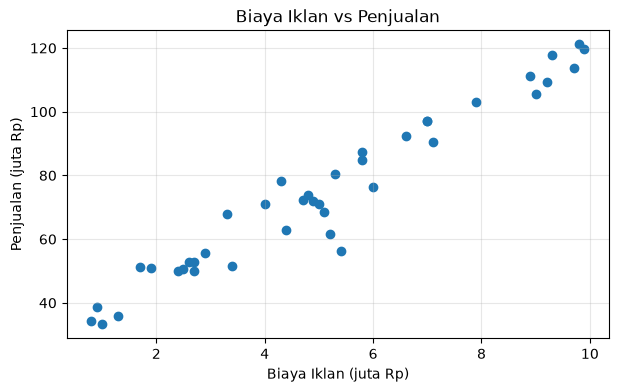

In [3]:
# Jawaban A1
ads = pd.read_csv('Ads_Data.csv')
display(ads.head())
print('Jumlah baris data:', len(ads))

X = ads[['BiayaIklan']].to_numpy()  # bentuk (n, 1)
y = ads['Penjualan'].to_numpy()
print('Shape X:', X.shape, '| Shape y:', y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
linear_model = LinearRegression().fit(X_train, y_train)
print(f'Intercept (b): {linear_model.intercept_:.4f}')
print(f'Koefisien (m): {linear_model.coef_[0]:.4f}')
print(f'Persamaan: ŷ = {linear_model.intercept_:.4f} + ({linear_model.coef_[0]:.4f})X')


Intercept (b): 29.3864
Koefisien (m): 9.0711
Persamaan: ŷ = 29.3864 + (9.0711)X


**Jawaban A3 (interpretasi):**

Nilai koefisien menunjukkan perkiraan perubahan penjualan untuk setiap kenaikan biaya iklan sebesar Rp1 juta per bulan. Jika koefisien bernilai positif, penjualan diperkirakan meningkat sebesar nilai koefisien tersebut (dalam juta rupiah), dengan asumsi hubungan linear pada data ini.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mae = np.mean(np.abs(y_true-y_pred))
    mse = np.mean((y_true-y_pred)**2)
    rmse = np.sqrt(mse)
    denom = np.sum((y_true-np.mean(y_true))**2)
    r2 = 1 - np.sum((y_true-y_pred)**2) / denom if denom != 0 else np.nan
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2}

metrics_rows = []
for name, X_part, y_part in [
    ('Training', X_train, y_train), ('Testing', X_test, y_test)
]:
    metrics_rows.append({'Data': name, **regression_metrics(y_part, linear_model.predict(X_part))})
metrics_table = pd.DataFrame(metrics_rows)
display(metrics_table.round(4))


,Data,MAE,MSE,RMSE,R²
0,Training,3.7920,24.4404,4.9437,0.9618
1,Testing,7.2023,87.1316,9.3344,0.8464


**Jawaban A4 (analisis):**

Pada data training, RMSE = 4,9437 dan R² = 0,9618, sedangkan pada data testing RMSE = 9,3344 dan R² = 0,8464. Artinya, kesalahan prediksi pada testing rata-rata sekitar Rp9,33 juta dan model menjelaskan sekitar 84,64% variasi penjualan pada data testing. Hasil testing masih cukup baik karena R² cukup tinggi, tetapi RMSE testing lebih besar daripada training sehingga prediksi pada data baru kurang akurat dibanding data yang dipakai untuk melatih model.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

learning_rate=0.001: intercept=26.2690, koefisien=9.5481
  MSE akhir: 26.60006820282404
learning_rate=0.02: intercept=29.3864, koefisien=9.0711
  MSE akhir: 24.440353387159966


C:\Users\User\AppData\Local\Temp\ipykernel_9192\2215872191.py:44: RuntimeWarning: overflow encountered in matmul
  gradient = (2 / len(X_b)) * (X_b.T @ errors)
C:\Users\User\AppData\Local\Temp\ipykernel_9192\2215872191.py:45: RuntimeWarning: invalid value encountered in subtract
  theta -= self.learning_rate * gradient


learning_rate=0.1: intercept=nan, koefisien=nan
  MSE akhir: nan


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


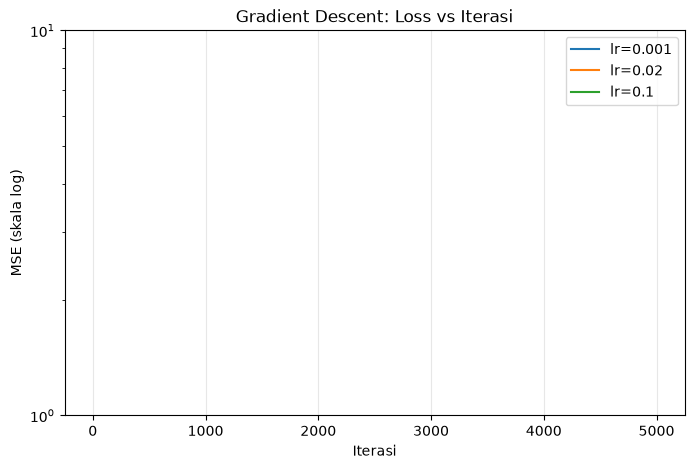

Normal equation: 29.38638853149599 9.071078601051479


In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
plt.figure(figsize=(8, 5))
for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model_gd
    print(f'learning_rate={lr}: intercept={model_gd.intercept_:.4f}, koefisien={model_gd.coef_[0]:.4f}')
    print('  MSE akhir:', model_gd.loss_history[-1])
    losses = np.asarray(model_gd.loss_history)
    losses[~np.isfinite(losses)] = np.nan
    plt.plot(losses, label=f'lr={lr}')
plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.title('Gradient Descent: Loss vs Iterasi')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print('Normal equation:', linear_model.intercept_, linear_model.coef_[0])


**Jawaban A5 (analisis):**

Learning rate `0.001` masih terlalu lambat: setelah 5.000 iterasi, koefisiennya belum mendekati hasil normal equation. Learning rate `0.02` konvergen dengan hasil yang hampir sama dengan normal equation (intercept sekitar 29,3864 dan koefisien 9,0711). Learning rate `0.1` gagal konvergen karena loss mengalami overflow dan parameter menjadi `nan`; langkah pembaruannya terlalu besar sehingga melewati nilai minimum.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

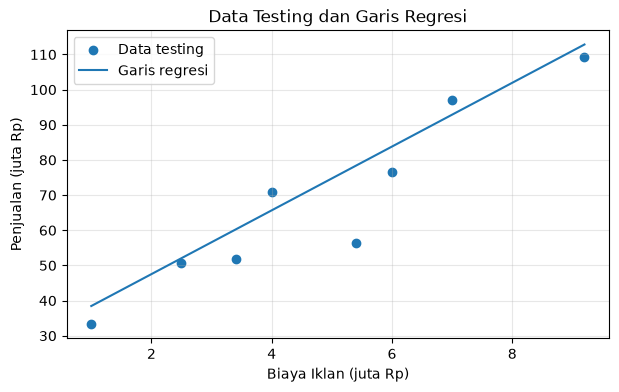

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,70.206
1,7.0,92.884
2,12.0,138.239


In [8]:
# Jawaban A6
y_test_pred = linear_model.predict(X_test)
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label='Data testing')
x_line = np.linspace(X_test[:, 0].min(), X_test[:, 0].max(), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], linear_model.predict(x_line), label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = linear_model.predict(biaya_baru)
display(pd.DataFrame({'BiayaIklan (juta Rp)': biaya_baru[:, 0],
                      'PrediksiPenjualan (juta Rp)': prediksi_penjualan}).round(3))


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan Rp12 juta merupakan ekstrapolasi karena berada di luar rentang biaya iklan pada dataset. Hasilnya perlu dianggap lebih tidak pasti dibanding prediksi pada rentang data yang diamati, sebab pola hubungan biaya iklan dan penjualan belum tentu tetap linear di luar rentang tersebut.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email per kelas:


,Jumlah
Spam,
Bukan Spam,35
Spam,25


Shape X: (60, 2) | Shape y: (60,)


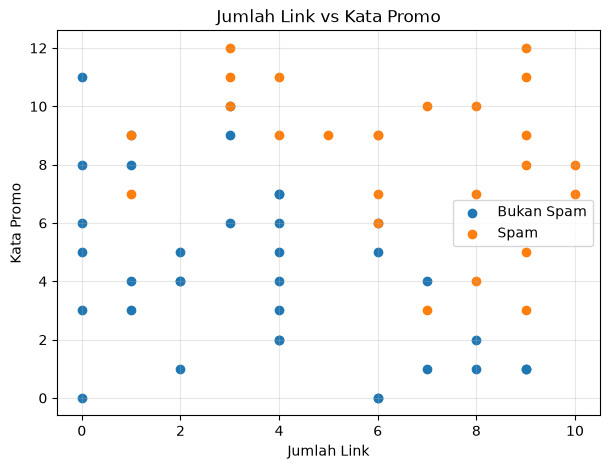

In [9]:
# Jawaban B1
email = pd.read_csv('Email_Data.csv')
display(email.head())
print('Jumlah email per kelas:')
display(email['Spam'].value_counts().rename(index={0: 'Bukan Spam', 1: 'Spam'}).to_frame('Jumlah'))

X_email = email[['JumlahLink', 'KataPromo']].to_numpy()
y_email = email['Spam'].to_numpy()
print('Shape X:', X_email.shape, '| Shape y:', y_email.shape)

plt.figure(figsize=(7, 5))
for label, name in [(0, 'Bukan Spam'), (1, 'Spam')]:
    subset = email[email['Spam'] == label]
    plt.scatter(subset['JumlahLink'], subset['KataPromo'], label=name)
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -11.191095
Koefisien: [1.02640651 0.87779514]
P(Spam) = sigmoid(-11.191095 + (1.026407)*JumlahLink + (0.877795)*KataPromo)


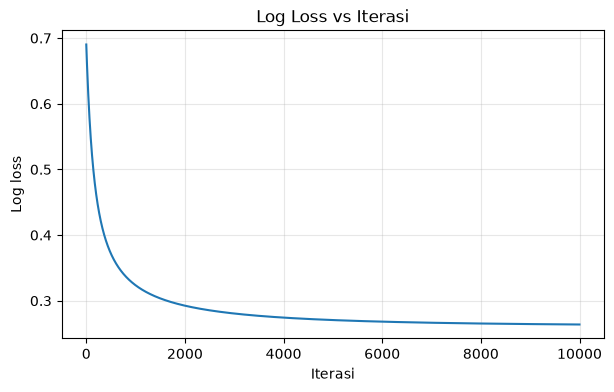

Loss awal: 0.6902414061054023 | Loss akhir: 0.263807791695201


In [10]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print(f'Intercept (b): {log_model.intercept_:.6f}')
print('Koefisien:', log_model.coef_)
print(f'P(Spam) = sigmoid({log_model.intercept_:.6f} + ({log_model.coef_[0]:.6f})*JumlahLink + ({log_model.coef_[1]:.6f})*KataPromo)')
plt.figure(figsize=(7, 4))
plt.plot(log_model.loss_history)
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.title('Log Loss vs Iterasi')
plt.grid(alpha=0.3)
plt.show()
print('Loss awal:', log_model.loss_history[0], '| Loss akhir:', log_model.loss_history[-1])


**Jawaban B2 (analisis):**

Log loss turun dari sekitar 0,6902 menjadi 0,2638 setelah 10.000 iterasi. Ini menunjukkan model mempelajari pola pada data training dan loss akhirnya menjadi lebih kecil. Kurva dan nilai akhir dapat diperiksa untuk melihat apakah penurunannya sudah mulai stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
y_pred_email = log_model.predict(X_test_email, threshold=0.5)
cm = confusion_matrix(y_test_email, y_pred_email)
tn, fp = cm[0, 0], cm[0, 1]
fn, tp = cm[1, 0], cm[1, 1]
precision = tp/(tp+fp) if tp+fp else 0.0
recall = tp/(tp+fn) if tp+fn else 0.0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)
print(f'Accuracy : {accuracy_score(y_test_email, y_pred_email):.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall   : {recall:.4f}')
print(f'F1-score : {f1:.4f}')


Confusion matrix [[TN, FP], [FN, TP]]:
[[5 0]
 [1 9]]
Accuracy : 0.9333
Precision: 1.0000
Recall   : 0.9000
F1-score : 0.9474


**Jawaban B3 (analisis):**

Pada hasil testing, model memperoleh accuracy 0,9333, precision 1,0000, recall 0,9000, dan F1-score 0,9474. Confusion matrix menunjukkan TN=5, FP=0, FN=1, dan TP=9. FP berarti email bukan spam salah masuk kategori spam, sedangkan FN berarti email spam lolos sebagai bukan spam. Dalam kasus ini terdapat satu FN dan tidak ada FP; prioritas kesalahan tergantung kebutuhan pengguna, tetapi FN bisa berisiko jika email spam berisi penipuan atau tautan berbahaya.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-11.191095 + (1.026407)*JumlahLink)/(0.877795)


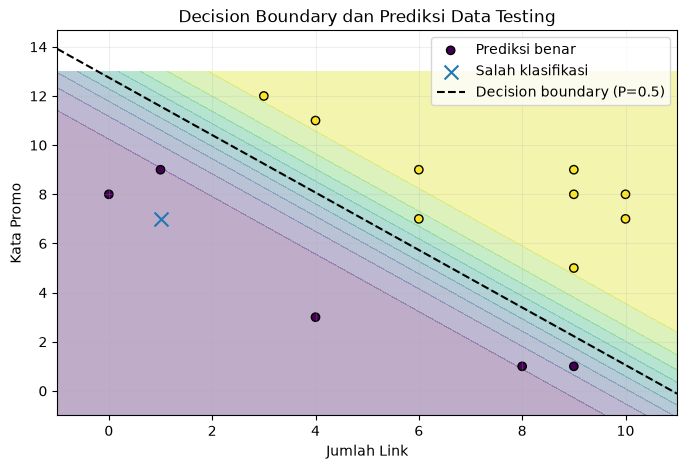

Data testing yang salah diklasifikasikan (indeks asli):


,JumlahLink,KataPromo,Aktual,Prediksi
4,1,7,1,0


In [12]:
# Jawaban B4
b = log_model.intercept_
m1, m2 = log_model.coef_
if abs(m2) > 1e-12:
    print(f'Decision boundary: KataPromo = -({b:.6f} + ({m1:.6f})*JumlahLink)/({m2:.6f})')
else:
    print('Koefisien KataPromo mendekati nol; decision boundary tidak dapat ditulis sebagai KataPromo = ... dengan pembagian m2.')

x1_min, x1_max = X_email[:, 0].min()-1, X_email[:, 0].max()+1
x2_min, x2_max = X_email[:, 1].min()-1, X_email[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 150), np.linspace(x2_min, x2_max, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = log_model.predict_proba(grid)[:, 1].reshape(xx.shape)
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, probs, levels=np.linspace(0, 1, 11), alpha=0.35)
correct = y_pred_email == y_test_email
plt.scatter(X_test_email[correct, 0], X_test_email[correct, 1], c=y_test_email[correct], edgecolors='black', label='Prediksi benar')
plt.scatter(X_test_email[~correct, 0], X_test_email[~correct, 1], marker='x', s=100, label='Salah klasifikasi')
if abs(m2) > 1e-12:
    boundary_x = np.linspace(x1_min, x1_max, 100)
    boundary_y = -(b + m1*boundary_x)/m2
    plt.plot(boundary_x, boundary_y, 'k--', label='Decision boundary (P=0.5)')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Decision Boundary dan Prediksi Data Testing')
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print('Data testing yang salah diklasifikasikan (indeks asli):')
test_indices = np.arange(len(email))[np.isin(np.arange(len(email)), [])]
# Cetak baris test beserta aktual dan prediksi agar kesalahan dapat diidentifikasi.
error_table = pd.DataFrame(X_test_email, columns=['JumlahLink', 'KataPromo'])
error_table['Aktual'] = y_test_email
error_table['Prediksi'] = y_pred_email
display(error_table[error_table['Aktual'] != error_table['Prediksi']])


**Jawaban B4 (analisis):**

Garis decision boundary menunjukkan batas probabilitas spam sebesar 0,5. Titik testing yang ditandai silang adalah email yang diprediksi berbeda dari label sebenarnya. Titik di sekitar batas lebih mudah salah klasifikasi karena probabilitas modelnya cenderung dekat dengan ambang keputusan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
prob_test = log_model.predict_proba(X_test_email)[:, 1]
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    cm_t = confusion_matrix(y_test_email, pred)
    tn_t, fp_t = cm_t[0, 0], cm_t[0, 1]
    fn_t, tp_t = cm_t[1, 0], cm_t[1, 1]
    p_t = tp_t/(tp_t+fp_t) if tp_t+fp_t else 0.0
    r_t = tp_t/(tp_t+fn_t) if tp_t+fn_t else 0.0
    threshold_rows.append({'Threshold': threshold, 'TN': tn_t, 'FP': fp_t, 'FN': fn_t, 'TP': tp_t,
                           'Precision': p_t, 'Recall': r_t})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,5,0,1,9,1.0,0.9
1,0.5,5,0,1,9,1.0,0.9
2,0.7,5,0,1,9,1.0,0.9


**Jawaban B5 (analisis):**

Pada data testing ini, threshold 0,3, 0,5, dan 0,7 menghasilkan confusion matrix yang sama (TN=5, FP=0, FN=1, TP=9), sehingga precision tetap 1,0 dan recall 0,9 untuk ketiganya. Artinya, tidak ada probabilitas testing yang membuat kelas prediksi berubah ketika threshold digeser pada tiga nilai tersebut. Untuk pemakaian nyata, threshold 0,3 bisa dipilih jika ingin lebih sensitif mendeteksi spam, tetapi perlu memantau FP; berdasarkan hasil eksperimen ini, ketiga threshold belum menunjukkan perbedaan metrik.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
# Pilihan awal threshold 0.5; sesuaikan dengan threshold yang dipilih berdasarkan tabel B5.
THRESHOLD_PILIHAN = 0.5
email_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})
X_baru = email_baru[['JumlahLink', 'KataPromo']].to_numpy()
prob_baru = log_model.predict_proba(X_baru)[:, 1]
pred_baru = (prob_baru >= THRESHOLD_PILIHAN).astype(int)
email_baru['ProbabilitasSpam'] = prob_baru
email_baru['Prediksi'] = np.where(pred_baru == 1, 'Spam', 'Bukan Spam')
email_baru['Threshold'] = THRESHOLD_PILIHAN
display(email_baru.round(4))


,Email,JumlahLink,KataPromo,ProbabilitasSpam,Prediksi,Threshold
0,E1,1,2,0.0002,Bukan Spam,0.5
1,E2,5,6,0.3117,Bukan Spam,0.5
2,E3,9,10,0.9989,Spam,0.5
3,E4,2,11,0.6266,Spam,0.5


# Bagian C – Pemahaman Konsep

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena digunakan untuk memperkirakan peluang suatu data masuk ke kelas tertentu, misalnya spam atau bukan spam. Fungsi sigmoid mengubah nilai gabungan fitur menjadi probabilitas antara 0 dan 1. Probabilitas tersebut kemudian dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:**

Normal equation menghitung parameter secara langsung melalui operasi matriks, sehingga tidak membutuhkan proses iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient descent lebih cocok ketika data atau jumlah fitur sangat besar sehingga perhitungan matriks langsung menjadi mahal, tetapi learning rate dan jumlah iterasi perlu dipilih dengan tepat.

**Jawaban C3:**

Data training digunakan untuk mempelajari parameter model, sedangkan data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai saat belajar. Jika hanya mengukur hasil pada training, performa model bisa terlihat terlalu bagus. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data baru.

**Jawaban C4:**

Linear Regression menghasilkan prediksi berupa nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss mengukur seberapa baik probabilitas yang diprediksi sesuai dengan label sebenarnya. Log loss memberi penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi salah.

**Jawaban C5:**

Hasil dapat berbeda karena pembagian data training dan testing bergantung pada `random_state`. Jika pembagian datanya berbeda, model mempelajari contoh yang berbeda sehingga koefisien dan metrik evaluasinya juga dapat berubah. Hasil juga dapat dipengaruhi oleh inisialisasi parameter, learning rate, jumlah iterasi, dan detail implementasi algoritma.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
# Bonus ini satu-satunya bagian yang menggunakan scikit-learn untuk membandingkan hasil.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score as sk_accuracy_score

sk_linear = SklearnLinearRegression().fit(X_train, y_train)
sk_pred_test = sk_linear.predict(X_test)
print('Linear Regression - implementasi sendiri')
print('Intercept:', linear_model.intercept_, '| Koefisien:', linear_model.coef_)
print('R² testing:', regression_metrics(y_test, linear_model.predict(X_test))['R²'])
print('\nLinear Regression - scikit-learn')
print('Intercept:', sk_linear.intercept_, '| Koefisien:', sk_linear.coef_)
print('R² testing:', sk_linear.score(X_test, y_test))

# Scaling tidak digunakan agar perbandingan memakai fitur dan split yang sama.
sk_log = SklearnLogisticRegression(max_iter=10000, random_state=RANDOM_STATE).fit(X_train_email, y_train_email)
sk_log_pred = sk_log.predict(X_test_email)
print('\nLogistic Regression - implementasi sendiri')
print('Intercept:', log_model.intercept_, '| Koefisien:', log_model.coef_)
print('Accuracy testing:', accuracy_score(y_test_email, log_model.predict(X_test_email)))
print('\nLogistic Regression - scikit-learn')
print('Intercept:', sk_log.intercept_[0], '| Koefisien:', sk_log.coef_[0])
print('Accuracy testing:', sk_accuracy_score(y_test_email, sk_log_pred))


Linear Regression - implementasi sendiri
Intercept: 29.38638853149599 | Koefisien: [9.0710786]
R² testing: 0.846418087371546

Linear Regression - scikit-learn
Intercept: 29.386388531495932 | Koefisien: [9.0710786]
R² testing: 0.8464180873715453

Logistic Regression - implementasi sendiri
Intercept: -11.191095198350043 | Koefisien: [1.02640651 0.87779514]
Accuracy testing: 0.9333333333333333

Logistic Regression - scikit-learn
Intercept: -10.49792792021903 | Koefisien: [0.95367177 0.82417556]
Accuracy testing: 0.9333333333333333


**Jawaban Bonus (analisis):**

Pada Linear Regression, koefisien normal equation dan scikit-learn seharusnya sangat dekat karena keduanya meminimalkan jumlah kuadrat error pada data yang sama. Hasil Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2, sedangkan implementasi gradient descent sederhana di notebook ini tidak memakai regularisasi. Parameter `C` pada scikit-learn mengatur kebalikan kekuatan regularisasi; nilai `C` lebih besar berarti regularisasi lebih lemah. Perbedaan optimisasi dan toleransi konvergensi juga dapat memengaruhi hasil.